# Open-system Qualtran resources: Appendix H

Uniform worked example: 4x4 lattice, N=1, cutoff 3, coupling 1, hopping 0.05, original potential 1, zero detuning, and the manuscript's charge-removed energy frame. Photon loss and relaxation rates are both 0.1; dephasing has zero weight; T=10.

The implementation shares preparation across the full dilation, reuses the jump signal, uses one-CCX relaxation, simplified dephasing and three reusable enable flags, and reflects on h,beta,f,A while excluding the physical dilation qubit d. Every coherent Toffoli is expanded into seven T gates. The generic rotation schedule does not generate numerical GQSP phases.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
os.environ.setdefault('MPLCONFIGDIR','/tmp/tcl-mpl')
os.environ.setdefault('NUMBA_CACHE_DIR','/tmp/tcl-numba')
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'resource_estimation/gqsp.py').is_file())
sys.path.insert(0,str(ROOT/'resource_estimation'))
sys.path.insert(0,str(ROOT/'validation'))
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
import gqsp as resources
import validation as validate


## Correlated-moment shot bound and precision

Eqs. (126)--(129) give the tighter measurement-shot bound: target g(2) error 0.1, assumed occupation lower bound 0.5, failure probability 0.01 and one measurement time. Eq. (103), evaluated at channel tolerance e/3, assigns e/12 to sampling alone. H14--H15 determine b,B,K,m at per-step implementation tolerance e/(6N_step).

**Qualification:** the timestep prescription covers the stated sampling allowance; the dilation remainder still requires a budget. The occupation lower bound is assumed. These are conditional resource estimates, not a complete global-error certificate.

In [2]:
p=resources.open_plan()
fields=['epsilon_n','epsilon_phi','state_tolerance','N_shot','N_step','dt','epsilon_step','b','B','K','m']
display(pd.DataFrame({'quantity':fields,'derived':[p[k] if k in ('N_shot','N_step','b','B','K','m') else float(p[k]) for k in fields]}))
assert tuple(p[k] for k in ('b','B','K','m','N_step','N_shot'))==(33,24,6,48,251658240,1794879)


,quantity,derived
0,epsilon_n,1.976424e-02
1,epsilon_phi,1.875000e-02
2,state_tolerance,1.562500e-03
3,N_shot,1.794879e+06
4,N_step,2.516582e+08
5,dt,3.973643e-08
6,epsilon_step,1.034803e-12
7,b,3.300000e+01
8,B,2.400000e+01
9,K,6.000000e+00


In [3]:
tables=resources.ensure_resources('open')
r=json.loads(resources._point_path('open',resources.OPEN_CASES[0]).read_text())
assert r['sources_sha256']==resources.source_hashes()
display(pd.Series(r['components']))
display(pd.DataFrame(r['channels']))
display(pd.Series(r['totals']))
assert [row['T_step'] for row in r['channels']]==[429786,406602,406098]
assert r['totals']['peak_logical_qubits']==434
print('Mean T gates across measurement runs:',f"{r['totals']['total_mean_T']:.6e}")


C_dir          2564
C_F            1242
a               128
workspace_w     167
dtype: int64

,channel,probability,C_J,walk_Toffolis,T_step,peak_logical_qubits,arithmetic_T_step,synthesis_T_step
0,photon_loss,0.75,282,4435,429786,434,372540,57246
1,atomic_loss,0.25,6,4159,406602,434,349356,57246
2,dephasing,0.00,0,4153,406098,434,348852,57246


mean_T_step            4.239900e+05
worst_T_step           4.297860e+05
mean_T_run             1.067006e+14
worst_T_run            1.081592e+14
N_shot                 1.794879e+06
N_step                 2.516582e+08
total_mean_T           1.915146e+20
peak_logical_qubits    4.340000e+02
dtype: float64

Mean T gates across measurement runs: 1.915146e+20


## Table VII-style extension and heatmaps

Vary lattice 4x4,4x8,8x8 and N=1,2,4; keep cutoff 3 and the example's rates, evolution time and observable targets. Recompute every point's timestep, shot count, precision and compiled circuit cost. The second T panel includes the shot multiplier; no additional trajectory multiplier is applied. This extension is not a separately printed manuscript Table VII.

Preparation and physical error correction are excluded; both reusable catalysts and the verified scratch allocation are included.

,lattice,Lx,Ly,L,N,n_max,b,B,K,m,mean_T_step,worst_T_step,mean_T_run,worst_T_run,N_shot,N_step,total_mean_T,peak_logical_qubits
0,4x4,4,4,16,1,3,33,24,6,48,423990.0,429786,1.067006e+14,108159188336640,1794879,251658240,1.915146e+20,434
1,4x4,4,4,16,2,3,34,25,6,49,442293.6,451836,1.739169e+14,177669144576000,1794879,393216000,3.121598e+20,460
2,4x4,4,4,16,4,3,34,26,6,50,560550.0,574182,4.320178e+14,442523996651520,1794879,770703360,7.754196e+20,502
3,4x8,4,8,32,1,3,35,25,6,50,655914.0,662046,6.602647e+14,666437324636160,1936835,1006632960,1.278824e+21,505
4,4x8,4,8,32,2,3,35,26,6,51,687724.8,697536,1.081698e+15,1097129263104000,1936835,1572864000,2.095070e+21,543
5,4x8,4,8,32,4,3,36,27,6,52,926442.0,940842,2.856048e+15,2900440362516480,1936835,3082813440,5.531693e+21,621
6,8x8,8,8,64,1,3,36,26,6,52,1105734.0,1112034,4.452273e+15,4477640308162560,2078792,4026531840,9.255350e+21,619
7,8x8,8,8,64,2,3,36,27,6,53,1169700.0,1179780,7.359116e+15,7422533959680000,2078792,6291456000,1.529807e+22,689
8,8x8,8,8,64,4,3,37,28,6,54,1644846.0,1659630,2.028301e+16,20465318677708800,2078792,12331253760,4.216417e+22,831


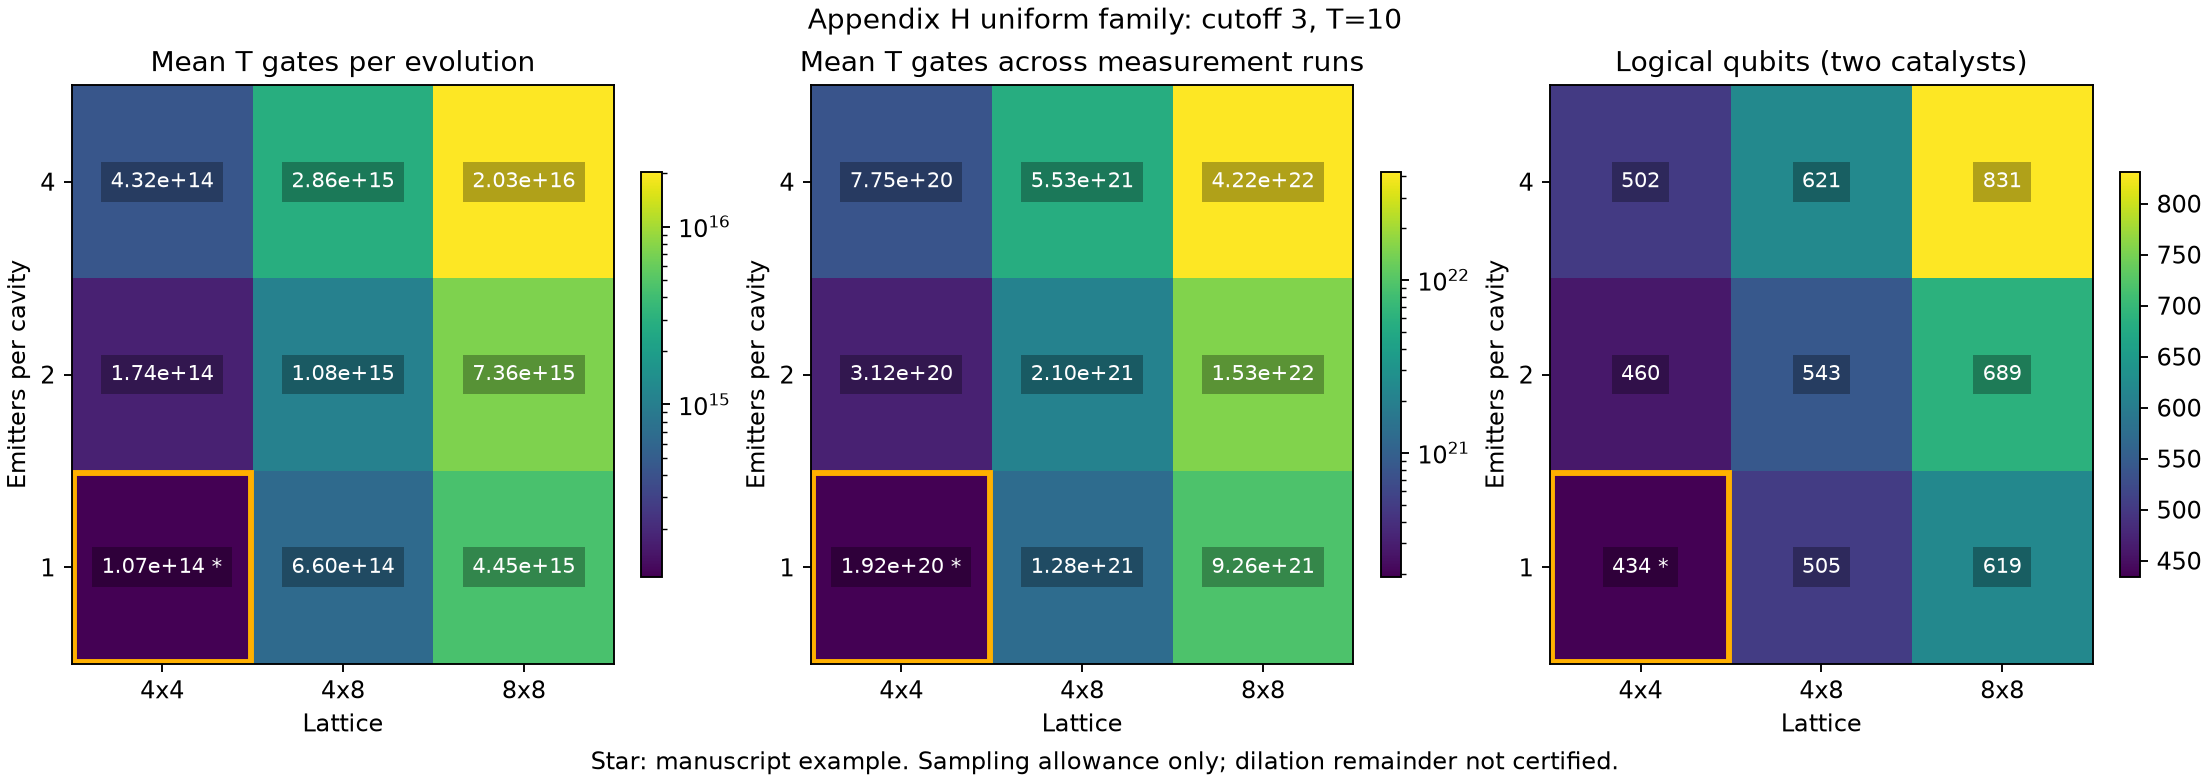

In [4]:
display(tables['VII_style'])
if 'VI' in resources.collect_tables():
    resources.resource_heatmaps()
    display(Image(filename=str(resources.RESULTS/'open_resource_heatmaps.png')))
